# Lab Exercise 4 — ARIMA Forecasting (AirPassengers)
Run cells top to bottom (Kernel → Restart & Run All at the end).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error

def metrics(actual, pred):
    return mean_absolute_error(actual, pred), np.sqrt(mean_squared_error(actual, pred))

def adf(x, name):
    stat, p = adfuller(x)[:2]
    print(f"{name}: ADF={stat:.3f}, p={p:.4f} ->", "stationary" if p < 0.05 else "NOT stationary")

## 1. Load data and Figure 1 (original series)

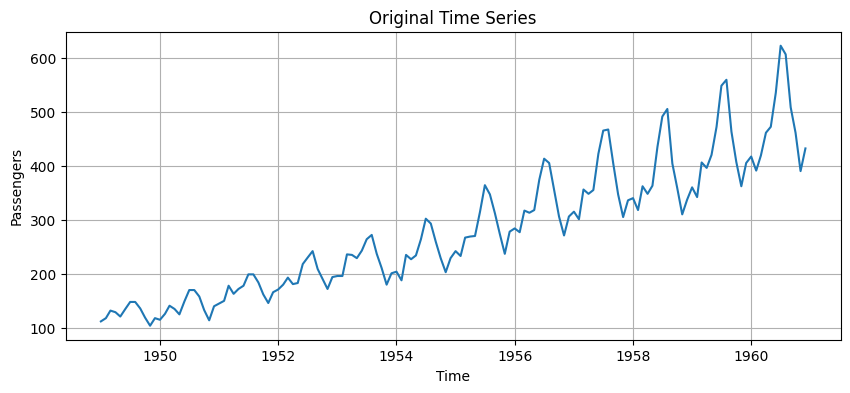

Original: ADF=0.815, p=0.9919 -> NOT stationary


In [2]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url, parse_dates=["Month"], index_col="Month")
series = df["Passengers"].astype(float).asfreq("MS")

plt.figure(figsize=(10, 4)); plt.plot(series)
plt.title("Original Time Series"); plt.xlabel("Time"); plt.ylabel("Passengers"); plt.grid(); plt.show()
adf(series, "Original")

## 2. Figure 2 (differenced) and Figure 3 (ACF / PACF)

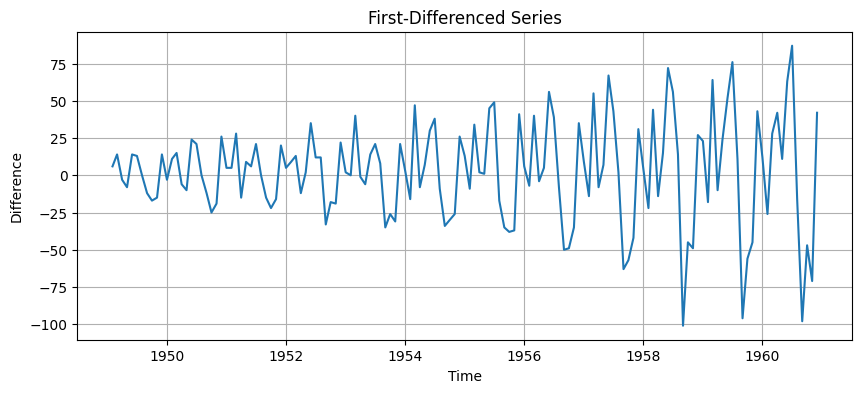

d=1: ADF=-2.829, p=0.0542 -> NOT stationary


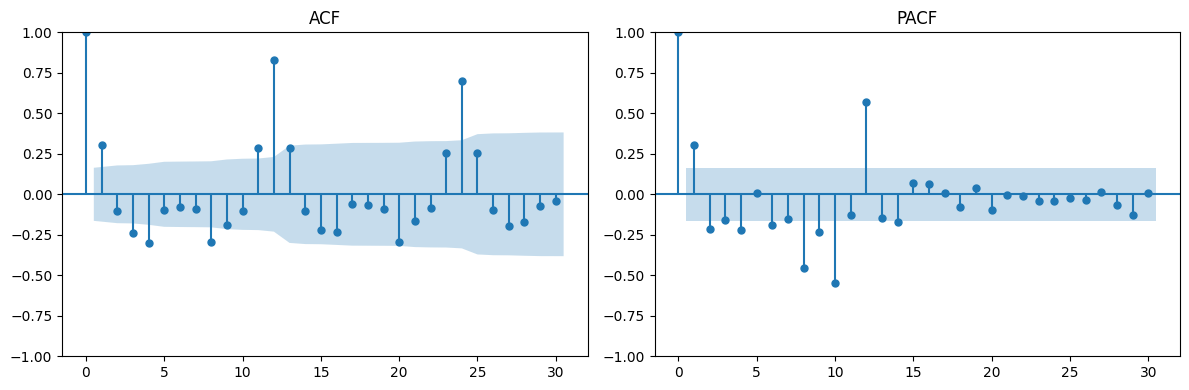

In [3]:
diff_series = series.diff().dropna()
plt.figure(figsize=(10, 4)); plt.plot(diff_series)
plt.title("First-Differenced Series"); plt.xlabel("Time"); plt.ylabel("Difference"); plt.grid(); plt.show()
adf(diff_series, "d=1")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(diff_series, ax=ax[0], lags=30); plot_pacf(diff_series, ax=ax[1], lags=30, method="ywm")
ax[0].set_title("ACF"); ax[1].set_title("PACF"); plt.tight_layout(); plt.show()

## 3. Train/test split (80/20, no shuffling), fit ARIMA(2,1,2), Figure 4 (forecast)

train: 115 test: 29
                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -523.758
Date:                Fri, 30 Oct 2026   AIC                           1057.516
Time:                        10:32:10   BIC                           1071.197
Sample:                    01-01-1949   HQIC                          1063.069
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3280      0.145      2.268      0.023       0.045       0.611
ar.L2          0.2521      0.165      1.528      0.126      -0.071       0.575
ma.L1         -0.0125      0.109

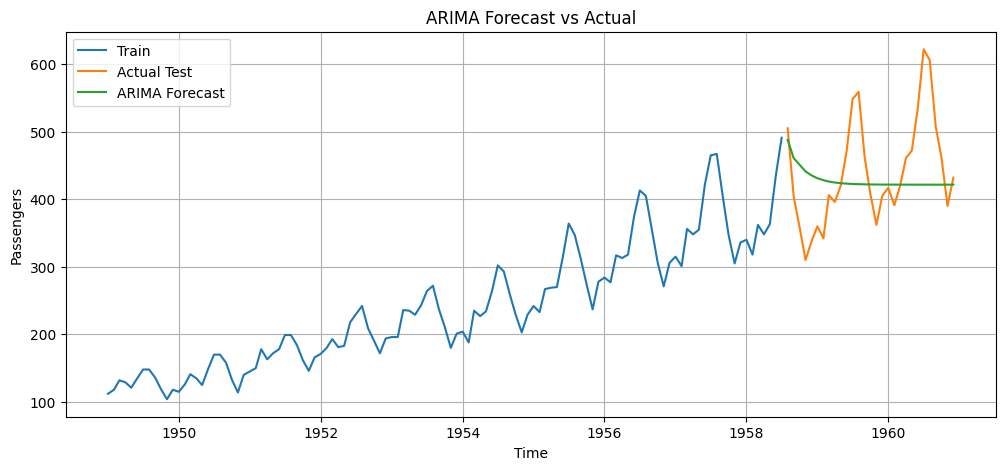

In [4]:
train_size = int(len(series) * 0.80)
train, test = series.iloc[:train_size], series.iloc[train_size:]
print("train:", len(train), "test:", len(test))

model_fit = ARIMA(train, order=(2, 1, 2)).fit()
print(model_fit.summary())

forecast = model_fit.forecast(steps=len(test))
mae, rmse = metrics(test, forecast)
print(f"(p,d,q) = (2,1,2)   MAE = {mae:.2f}   RMSE = {rmse:.2f}")

plt.figure(figsize=(12, 5))
plt.plot(train, label="Train"); plt.plot(test, label="Actual Test"); plt.plot(test.index, forecast, label="ARIMA Forecast")
plt.title("ARIMA Forecast vs Actual"); plt.xlabel("Time"); plt.ylabel("Passengers"); plt.legend(); plt.grid(); plt.show()

## 4. Figure 5 (residuals)
Change from the handout: the first residual is dropped, because with d=1 it just equals the first observation (a huge fake spike).

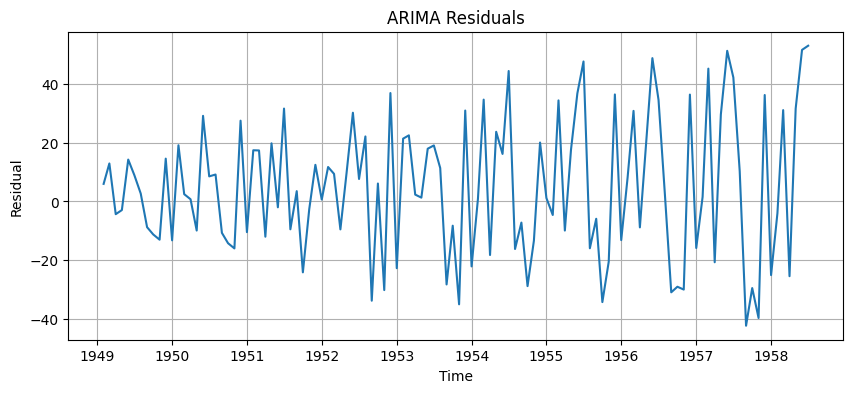

In [5]:
resid = model_fit.resid.iloc[1:]
plt.figure(figsize=(10, 4)); plt.plot(resid)
plt.title("ARIMA Residuals"); plt.xlabel("Time"); plt.ylabel("Residual"); plt.grid(); plt.show()

## Task 4.1 — Compare ARIMA orders

In [6]:
rows = []
for order in [(1,1,1), (2,1,1), (1,1,2), (2,1,2)]:
    fit = ARIMA(train, order=order).fit()
    m, r = metrics(test, fit.forecast(len(test)))
    rows.append([order, fit.aic, m, r])
pd.DataFrame(rows, columns=["order", "AIC", "MAE", "RMSE"]).round(2)

,order,AIC,MAE,RMSE
0,"(1, 1, 1)",1058.25,85.25,97.50
1,"(2, 1, 1)",1058.65,60.53,82.62
2,"(1, 1, 2)",1057.33,62.06,82.64
3,"(2, 1, 2)",1057.52,63.55,82.51


## Task 4.2 — Effect of differencing (d=0 vs d=1)

d=0: AIC=1074.5  MAE=92.26  RMSE=114.90
d=1: AIC=1057.5  MAE=63.55  RMSE=82.51


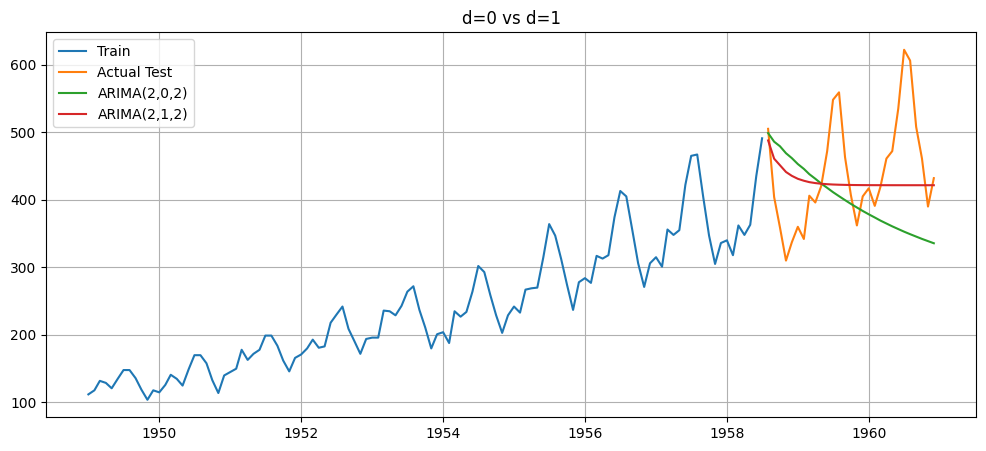

In [7]:
plt.figure(figsize=(12, 5)); plt.plot(train, label="Train"); plt.plot(test, label="Actual Test")
for d in [0, 1]:
    fit = ARIMA(train, order=(2, d, 2)).fit()
    fc = fit.forecast(len(test)); m, r = metrics(test, fc)
    print(f"d={d}: AIC={fit.aic:.1f}  MAE={m:.2f}  RMSE={r:.2f}")
    plt.plot(test.index, fc, label=f"ARIMA(2,{d},2)")
plt.title("d=0 vs d=1"); plt.legend(); plt.grid(); plt.show()

## Task 4.3 — Forecast horizon (6, 12, 24) with 95% intervals

h= 6: MAE=77.79  RMSE=85.58  final 95% interval width=216.5
h=12: MAE=64.98  RMSE=76.77  final 95% interval width=256.6
h=24: MAE=62.10  RMSE=79.92  final 95% interval width=313.8


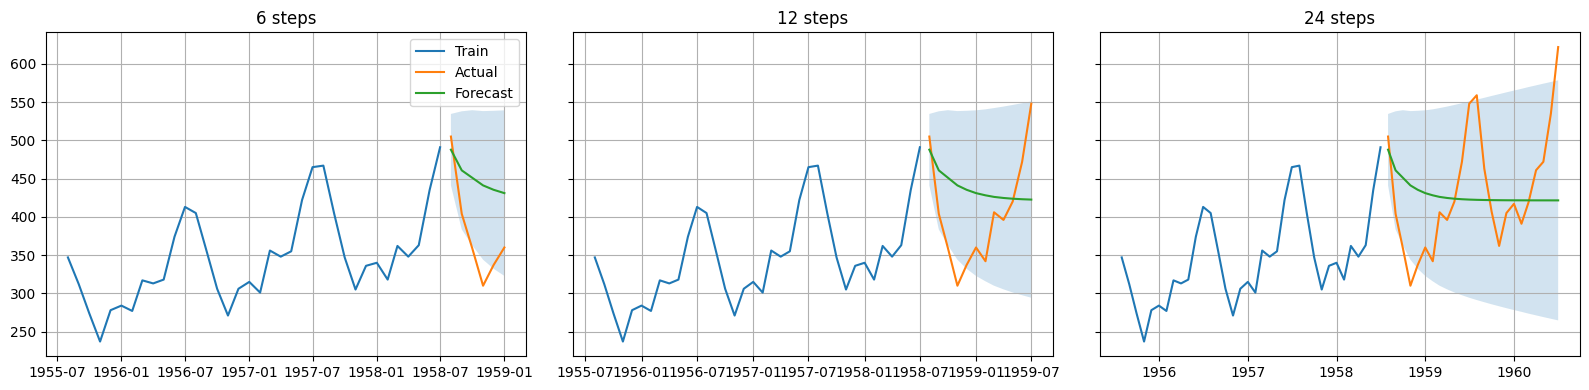

In [8]:
fit = ARIMA(train, order=(2, 1, 2)).fit()
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, h in zip(axes, [6, 12, 24]):
    f = fit.get_forecast(h); mean, ci = f.predicted_mean, f.conf_int()
    m, r = metrics(test.iloc[:h], mean)
    print(f"h={h:2d}: MAE={m:.2f}  RMSE={r:.2f}  final 95% interval width={ci.iloc[-1,1]-ci.iloc[-1,0]:.1f}")
    ax.plot(train.iloc[-36:], label="Train"); ax.plot(test.iloc[:h], label="Actual"); ax.plot(mean, label="Forecast")
    ax.fill_between(ci.index, ci.iloc[:,0], ci.iloc[:,1], alpha=0.2); ax.set_title(f"{h} steps"); ax.grid()
axes[0].legend(); plt.tight_layout(); plt.show()

## Task 4.4 — Residual ACF and Ljung-Box test

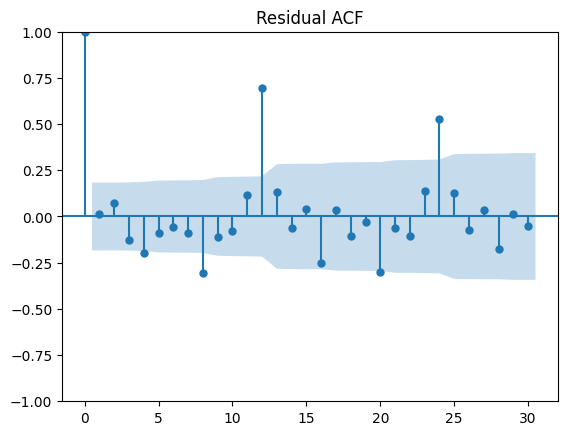

       lb_stat     lb_pvalue
12   87.832667  1.295587e-13
24  160.054493  4.388510e-22


In [9]:
plot_acf(resid, lags=30); plt.title("Residual ACF"); plt.show()
print(acorr_ljungbox(resid, lags=[12, 24]))   # p < 0.05 => autocorrelation remains

## Task 4.5 — New real dataset: Daily Total Female Births (California, 1959)
Source: https://github.com/jbrownlee/Datasets (daily-total-female-births.csv). Frequency: daily.

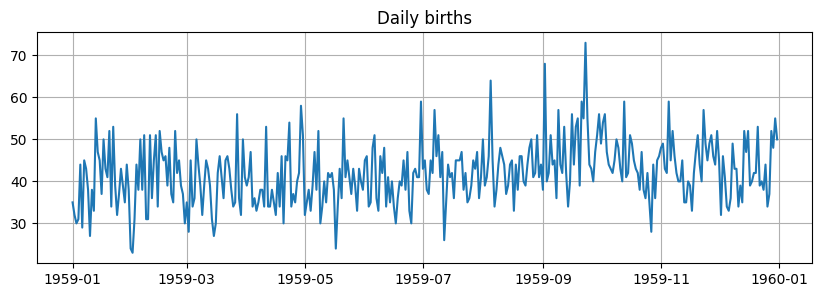

Births: ADF=-4.808, p=0.0001 -> stationary
train: 292 test: 73
       order      AIC   MAE  RMSE
0  (0, 0, 1)  2003.56  5.30  6.56
1  (1, 0, 1)  1984.40  5.71  6.97
2  (2, 0, 2)  1985.50  5.73  6.96
3  (1, 1, 1)  1976.15  6.18  7.51
4  (0, 1, 1)  1975.61  6.22  7.56
Selected (d=0, lowest AIC): (1, 0, 1)
MAE, RMSE = [5.71, np.float64(6.97)]


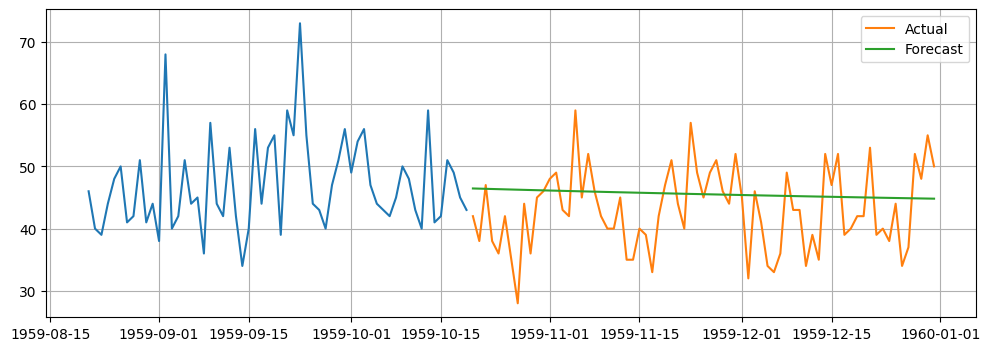

In [10]:
url2 = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-total-female-births.csv"
s2 = pd.read_csv(url2, parse_dates=["Date"], index_col="Date")["Births"].astype(float).asfreq("D")
plt.figure(figsize=(10, 3)); plt.plot(s2); plt.title("Daily births"); plt.grid(); plt.show()
adf(s2, "Births")

n = int(len(s2) * 0.8); tr2, te2 = s2.iloc[:n], s2.iloc[n:]
print("train:", len(tr2), "test:", len(te2))

rows = []
for order in [(0,0,1), (1,0,1), (2,0,2), (1,1,1), (0,1,1)]:
    fit = ARIMA(tr2, order=order).fit(); m, r = metrics(te2, fit.forecast(len(te2)))
    rows.append([order, fit.aic, m, r])
res = pd.DataFrame(rows, columns=["order", "AIC", "MAE", "RMSE"]).round(2); print(res)

cand = res[res["order"].apply(lambda o: o[1] == 0)]   # ADF says stationary -> d=0, so no differencing
best = cand.loc[cand["AIC"].idxmin(), "order"]; print("Selected (d=0, lowest AIC):", best)
fit = ARIMA(tr2, order=best).fit(); fc = fit.forecast(len(te2))
print("MAE, RMSE =", [round(v, 2) for v in metrics(te2, fc)])
plt.figure(figsize=(12, 4)); plt.plot(tr2.iloc[-60:]); plt.plot(te2, label="Actual"); plt.plot(te2.index, fc, label="Forecast")
plt.legend(); plt.grid(); plt.show()